# Melton / Jimenez - Local vs. global decay of Moran's I across all genes

Same analysis as `legnini_23/3b_moran_local_global` for the CosMx pancreas data (ND and T1D donors). The Moran
curve I(k) of each gene is split at `K_SPLIT` into

- **ΔI local** = I(k_min) − I(K_SPLIT): structure lost within small neighborhoods,
- **ΔI global** = I(K_SPLIT) − I(k_max): structure lost at tissue scale,

compared as **ΔI per doubling of k** and as **relative** loss (ΔI / I at the start of the range).

**Split matched to the local component.** Here `K_SPLIT` is not chosen by hand: InterScale's local component (GCN)
sees the neighbors within `radius` of the training config (`config_files/melton_jimenez_25`). `K_SPLIT` is the
median number of neighbors within this radius, so "local" in the Moran analysis covers the neighborhood one GCN
layer sees. With `num_layers` GCN layers the local component reaches `num_layers × radius`; the matching k is
included as a second split (`K_REACH`) for comparison.

Moran's I is computed per FOV (`slide_fov`, graphs within each FOV, per-FOV coordinates as for the local graph) and
averaged over the FOVs of each condition.

In [1]:
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yaml
from scipy.spatial import cKDTree
from scipy.stats import spearmanr

import matplotlib.pyplot as plt
import interscale as isc

import scanpy as sc

ROOT = Path.cwd()
while not (ROOT / "figures" / "config.yml").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Run this notebook from inside the InterScale_reproducibility repository.")
    ROOT = ROOT.parent

## Configuration

In [2]:
DATA = "melton25"
MELTON25 = "/lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/data/melton25.h5ad"
MODEL_CFG = ROOT / "config_files" / "melton_jimenez_25" / "regr_InterScale.yaml"

with open(ROOT / "figures" / "config.yml") as f:
    config = yaml.safe_load(f)
PLOT_CFG = config["plot_configs"]["general"]
CMAP = config["palettes"]["continuous"]
SLIDES = {"ND": config["slide_examples"]["Melton_Jimenez"]["Ctrl"], "T1D": config["slide_examples"]["Melton_Jimenez"]["T1D"]}
COLOR_GLOBAL = "#337F8F"
COLOR_LOCAL = "#EE9B00"
COLOR_OTHER = "#BBBBBB"
CLASS_COLORS = {"color_local": COLOR_LOCAL, "color_global": COLOR_GLOBAL, "color_other": COLOR_OTHER}
plt.rcParams.update({"font.family": PLOT_CFG["font_family"], "figure.dpi": PLOT_CFG["dpi"]})

# local component of the trained model: radius graph built within `library_key`
with open(MODEL_CFG) as f:
    model_cfg = yaml.safe_load(f)
RADIUS = float(model_cfg["dataset"]["spatial_neigbors_kwargs"]["radius"])  # px, per-FOV coordinates
LIBRARY_KEY = model_cfg["dataset"]["spatial_neigbors_kwargs"]["library_key"]  # slide_fov
NUM_LAYERS = 2  # GCN default (interscale/config/local_component_config.py), not overridden in MODEL_CFG
REACH = NUM_LAYERS * RADIUS
PX_UM = 0.12028  # µm per px (CosMx)

LAYER = None  # adata.X: log1p-normalized expression (model input)
CONDITIONS = ["ND", "T1D"]
CONDITION = "T1D"  # condition for sections 1-6; section 7 compares ND and T1D
BASE_KS = (4, 8, 16, 32, 64, 128)  # K_SPLIT and K_REACH are added
GRAPH = "knn"  # "knn" or "radius" (radii matched to KS; split exactly at RADIUS)
MIN_I = 0.1  # genes with mean Moran's I below this at k_min have no structure to lose; shown in grey
N_TOP = 8  # genes labelled / shown per category

# one marker per coarse cell type, colored as the cell type
MARKERS = {"Acinar": "REG1A", "Ductal": "KRT19", "Alpha": "GCG", "Beta": "INS", "Endocrine": "SST",
           "Endothelial": "PECAM1", "Fibroblasts": "COL1A1", "Immune": "PTPRC", "Mast": "TPSAB1"}
GENES = list(MARKERS.values())
GENE_COLORS = {g: config["palettes"][DATA][ct] for ct, g in MARKERS.items()}
N_TOP_GENES = 2  # genes highlighted per category when restricted to GENES

FIG_DIR = ROOT / "figures" / DATA / "moran_local_global" / GRAPH
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"local component: radius {RADIUS:.0f} px ({RADIUS * PX_UM:.1f} µm), {NUM_LAYERS} layers -> reach "
      f"{REACH:.0f} px ({REACH * PX_UM:.1f} µm); graphs within {LIBRARY_KEY!r}")

local component: radius 110 px (13.2 µm), 2 layers -> reach 220 px (26.5 µm); graphs within 'slide_fov'


## Matching `K_SPLIT` to the local component

Number of neighbors of each cell within `RADIUS` (one GCN layer) and within `REACH` (all GCN layers), counted within
each FOV on the same coordinates as the local graph. `K_SPLIT` / `K_REACH` are the medians over all cells of both
conditions, so both conditions are split at the same k.

386727 cells, 960 genes (of 979), 71 FOVs


,k within 110 px,k within 220 px
condition,,
ND,10.0,40.0
T1D,11.0,46.0


K_SPLIT = 11 (median neighbors within 110 px), K_REACH = 43 (within 220 px); KS = (4, 8, 11, 16, 32, 43, 64, 128)
cells without a neighbor within 110 px: 0.06%


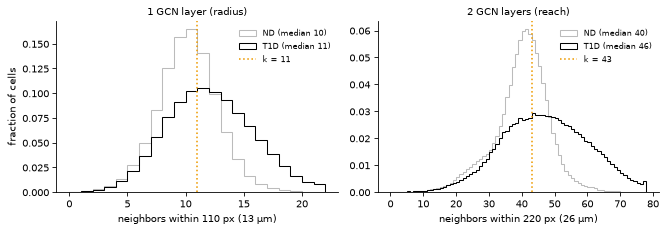

In [3]:
adata = sc.read_h5ad(MELTON25)
FEATURES = [g for g in adata.var_names if not g.startswith(("NegPrb", "SystemControl"))]  # no negative probes
print(f"{adata.n_obs} cells, {len(FEATURES)} genes (of {adata.n_vars}), {adata.obs[LIBRARY_KEY].nunique()} FOVs")

xy = np.asarray(adata.obsm["spatial"], dtype=float)
deg = {r: np.empty(adata.n_obs) for r in (RADIUS, REACH)}
for idx in adata.obs.groupby(LIBRARY_KEY, observed=True).indices.values():
    tree = cKDTree(xy[idx])
    for r in deg:
        deg[r][idx] = tree.query_ball_point(xy[idx], r, return_length=True) - 1  # without the cell itself
K_SPLIT = int(round(np.median(deg[RADIUS])))
K_REACH = int(round(np.median(deg[REACH])))
KS = tuple(sorted(set(BASE_KS) | {K_SPLIT, K_REACH}))

deg_df = pd.DataFrame({"condition": adata.obs["condition"].to_numpy(), "radius": deg[RADIUS], "reach": deg[REACH]})
display(deg_df.groupby("condition").median().rename(columns={"radius": f"k within {RADIUS:.0f} px",
                                                             "reach": f"k within {REACH:.0f} px"}))
print(f"K_SPLIT = {K_SPLIT} (median neighbors within {RADIUS:.0f} px), "
      f"K_REACH = {K_REACH} (within {REACH:.0f} px); KS = {KS}")
print(f"cells without a neighbor within {RADIUS:.0f} px: {np.mean(deg[RADIUS] == 0):.2%}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (col, r, k) in zip(axes, [("radius", RADIUS, K_SPLIT), ("reach", REACH, K_REACH)]):
    for cond, c in zip(CONDITIONS, [COLOR_OTHER, "k"]):
        v = deg_df.loc[deg_df["condition"] == cond, col]
        ax.hist(v, bins=np.arange(0, np.percentile(deg_df[col], 99.5) + 2), histtype="step", color=c, density=True,
                label=f"{cond} (median {np.median(v):.0f})")
    ax.axvline(k, ls=":", color=COLOR_LOCAL, label=f"k = {k}")
    ax.set_xlabel(f"neighbors within {r:.0f} px ({r * PX_UM:.0f} µm)")
    ax.set_title("1 GCN layer (radius)" if col == "radius" else f"{NUM_LAYERS} GCN layers (reach)", fontsize=10)
    ax.legend(frameon=False, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("fraction of cells")
plt.tight_layout()
plt.savefig(FIG_DIR / "k_split_matching.png", dpi=PLOT_CFG["dpi_save"], bbox_inches="tight")
plt.show()

## Moran's I for all genes, per FOV

In [4]:
if GRAPH == "knn":
    SCALE_COL, SCALES, XLABEL = "k", list(KS), "Number of neighbors (k)"
    SPLIT, SPLIT_REACH = K_SPLIT, K_REACH
else:
    SCALE_COL, XLABEL = "radius", "Radius (px)"
    radii = dict(zip(KS, isc.tl.radii_from_knn(adata, ks=KS, library_key=LIBRARY_KEY)))  # prints the radii
    radii[K_SPLIT], radii[K_REACH] = RADIUS, REACH  # split exactly at the local component's radius / reach
    SCALES = [radii[k] for k in KS]
    SPLIT, SPLIT_REACH = RADIUS, REACH
SCALE_NAME = "k" if GRAPH == "knn" else "r"


def fmt(s):
    return f"{SCALE_NAME} = {s:.0f}"


adatas = {}
for cond in CONDITIONS:
    adatas[cond] = adata[adata.obs["condition"] == cond].copy()
    # Moran curves per FOV, averaged over FOVs; AUC, local / global decay and local index of the mean curves
    isc.tl.moran_scale(
        adatas[cond], ks=KS, graph=GRAPH, radii=SCALES if GRAPH == "radius" else None, split=SPLIT,
        library_key=LIBRARY_KEY, genes=FEATURES, layer=LAYER, per_library=True,
    )
    res = adatas[cond].uns["moran_scale"]
    res["profile_per_library"].to_csv(FIG_DIR / f"moran_profile_{cond}_per_fov.csv", index=False)
    print(f"{cond}: {res['profile_per_library']['library'].nunique()} FOVs")

adata_cond = adatas[CONDITION]
prof = adata_cond.uns["moran_scale"]["profile"]
I = prof.pivot(index="feature", columns=SCALE_COL, values="I")[SCALES]

ND: 32 FOVs


T1D: 39 FOVs


## Summary statistics per gene

In [5]:
# local_index = slope_local - slope_global; positive: the gene loses its autocorrelation mainly within small
# neighborhoods (local pattern)
stats_all = {}
for cond in CONDITIONS:
    st = adatas[cond].uns["moran_scale"]["stats"].copy()
    st["structured"] = st["I_min"] >= MIN_I
    stats_all[cond] = st.sort_values("auc", ascending=False).reset_index(drop=True)
    stats_all[cond].to_csv(FIG_DIR / f"moran_local_global_{cond}_split{K_SPLIT}.csv", index=False)
    print(f"{cond}: {st['structured'].sum()} / {len(st)} genes with mean I(k_min) >= {MIN_I}")
stats = stats_all[CONDITION]
display(stats.round(3).head(10))

ND: 39 / 960 genes with mean I(k_min) >= 0.1
T1D: 40 / 960 genes with mean I(k_min) >= 0.1


,feature,I_min,I_split,I_max,delta_local,delta_global,delta_total,slope_local,slope_global,rel_local,rel_global,chord_gap,auc,auc_norm,local_index,structured
0,GCG,0.679,0.621,0.394,0.058,0.227,0.284,0.039,0.064,0.085,0.365,-0.025,60.590,0.489,-0.025,True
1,TTR,0.660,0.610,0.392,0.050,0.218,0.268,0.034,0.062,0.076,0.357,-0.028,60.128,0.485,-0.027,True
2,CHGA,0.547,0.505,0.325,0.042,0.180,0.222,0.029,0.051,0.076,0.357,-0.023,49.876,0.402,-0.022,True
3,INS,0.425,0.396,0.269,0.029,0.127,0.156,0.020,0.036,0.068,0.321,-0.017,40.050,0.323,-0.016,True
4,PRSS2,0.528,0.443,0.246,0.085,0.196,0.281,0.058,0.055,0.162,0.443,0.003,39.548,0.319,0.003,True
5,REG1A,0.510,0.419,0.225,0.091,0.195,0.285,0.062,0.055,0.178,0.464,0.007,36.609,0.295,0.007,True
6,CPB1,0.461,0.386,0.217,0.075,0.169,0.244,0.052,0.048,0.163,0.438,0.004,34.600,0.279,0.004,True
7,SPINK1,0.388,0.310,0.165,0.078,0.145,0.223,0.053,0.041,0.201,0.468,0.013,26.707,0.215,0.012,True
8,SST,0.388,0.312,0.147,0.077,0.165,0.241,0.052,0.046,0.197,0.528,0.006,25.527,0.206,0.006,True
9,HLA-A,0.216,0.192,0.132,0.024,0.061,0.085,0.017,0.017,0.112,0.315,-0.000,19.266,0.155,-0.000,True


## 1. Highest and lowest AUC (`CONDITION`)

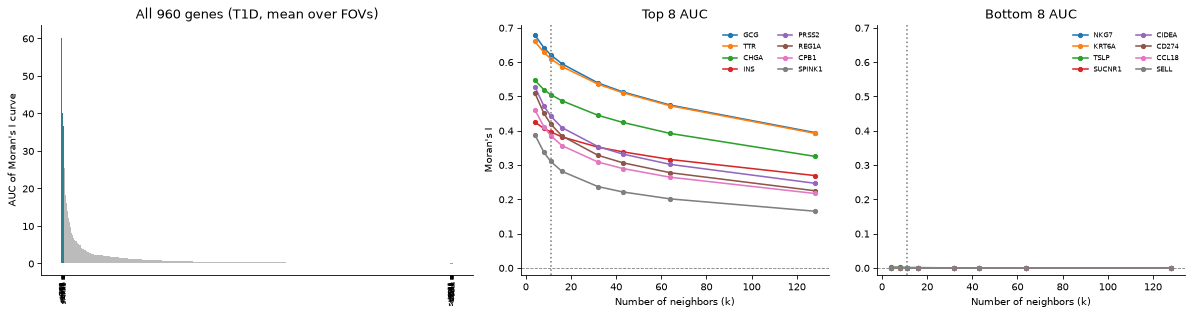

In [6]:
top_auc = stats.head(N_TOP)["feature"].tolist()
low_auc = stats.tail(N_TOP)["feature"].tolist()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), gridspec_kw={"width_ratios": [1.4, 1, 1]})
ax = axes[0]
colors = [COLOR_GLOBAL if g in top_auc else COLOR_LOCAL if g in low_auc else COLOR_OTHER for g in stats["feature"]]
ax.bar(range(len(stats)), stats["auc"], color=colors, width=1.0, linewidth=0)
shown = [i for i, g in enumerate(stats["feature"]) if g in top_auc or g in low_auc]  # too many genes to label all
ax.set_xticks(shown, stats["feature"].iloc[shown], rotation=90, fontsize=6)
ax.set_ylabel("AUC of Moran's I curve")
ax.set_title(f"All {len(stats)} genes ({CONDITION}, mean over FOVs)")
for ax, genes, title in [(axes[1], top_auc, f"Top {N_TOP} AUC"), (axes[2], low_auc, f"Bottom {N_TOP} AUC")]:
    for g, c in zip(genes, plt.get_cmap("tab10").colors):
        ax.plot(SCALES, I.loc[g], marker="o", ms=4, color=c, label=g)
    ax.set_title(title)
    ax.set_xlabel(XLABEL)
    ax.legend(frameon=False, fontsize=7, ncol=2)
axes[1].set_ylabel("Moran's I")
# common y-axis from 0 so both panels are comparable (bottom-AUC genes have I close to 0)
I_shown = I.loc[top_auc + low_auc]
ylim = (min(0, I_shown.values.min()) - 0.02, I_shown.values.max() + 0.03)
for a in axes[1:]:
    a.set_ylim(ylim)
    a.axhline(0, ls="--", lw=0.8, color="grey")
    a.axvline(SPLIT, ls=":", color="grey")
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / f"auc_ranking_{CONDITION}.png", dpi=PLOT_CFG["dpi_save"], bbox_inches="tight")
plt.show()

### Local vs. global genes by local index

**local index** = ΔI local − ΔI global (both per doubling of k), split at `K_SPLIT` (the local component's radius).
Top local = highest local index, top global = lowest local index. Genes with mean I(k_min) < `MIN_I` are excluded
(their slopes are noise). The dotted line marks the split.

top 8 local:  ['ANXA4', 'FGFR3', 'COL18A1', 'OLFM4', 'APOD', 'SOX9', 'CD74', 'IGFBP7']
top 8 global: ['TTR', 'GCG', 'CHGA', 'INS', 'SCG5', 'IAPP', 'TIMP1', 'GC']


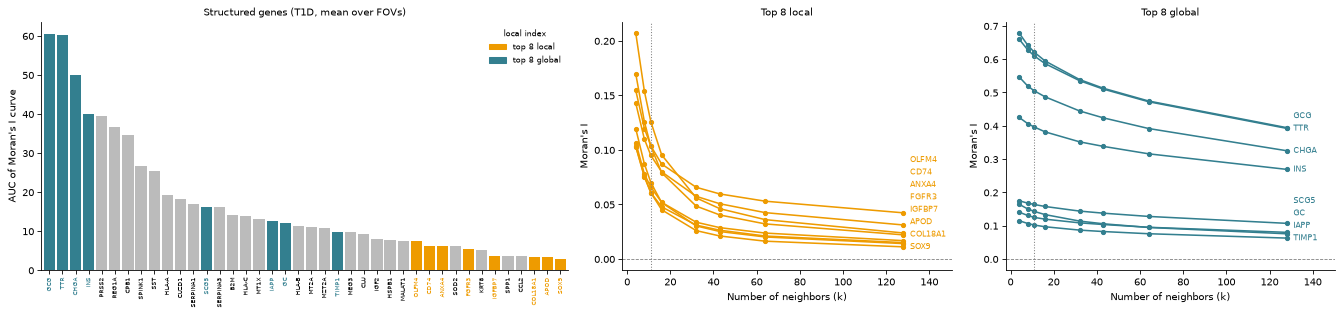

In [7]:
STRUCTURED = stats.loc[stats["structured"], "feature"].tolist()
top_li_local, top_li_global = isc.pl.top_local_global(adata_cond, n_top=N_TOP, features=STRUCTURED)
print(f"top {N_TOP} local:  {top_li_local}")
print(f"top {N_TOP} global: {top_li_global}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.3), gridspec_kw={"width_ratios": [1.6, 1, 1]})
isc.pl.moran_auc(adata_cond, features=STRUCTURED, n_top=N_TOP, ax=axes[0], **CLASS_COLORS,
                 title=f"Structured genes ({CONDITION}, mean over FOVs)")
isc.pl.moran_curves(adata_cond, genes="local", features=STRUCTURED, n_top=N_TOP, ax=axes[1], **CLASS_COLORS,
                    title=f"Top {N_TOP} local")
isc.pl.moran_curves(adata_cond, genes="global", features=STRUCTURED, n_top=N_TOP, ax=axes[2], **CLASS_COLORS,
                    title=f"Top {N_TOP} global")
plt.tight_layout()
plt.savefig(FIG_DIR / f"local_index_ranking_{CONDITION}_split{K_SPLIT}.png", dpi=PLOT_CFG["dpi_save"],
            bbox_inches="tight")
plt.show()

Restricted to the cell type markers (`GENES`): bars colored by the top `N_TOP_GENES` local / global markers (local
index), curves of all markers in their cell type color.

,I_min,I_split,I_max,slope_local,slope_global,rel_local,rel_global,local_index,auc
feature,,,,,,,,,
REG1A,0.510,0.419,0.225,0.062,0.055,0.178,0.464,0.007,36.609
KRT19,0.064,0.043,0.010,0.014,0.009,0.317,0.770,0.004,2.656
GCG,0.679,0.621,0.394,0.039,0.064,0.085,0.365,-0.025,60.590
INS,0.425,0.396,0.269,0.020,0.036,0.068,0.321,-0.016,40.050
SST,0.388,0.312,0.147,0.052,0.046,0.197,0.528,0.006,25.527
PECAM1,0.015,0.010,0.004,0.003,0.002,0.333,0.647,0.002,0.670
COL1A1,0.064,0.040,0.013,0.016,0.008,0.369,0.686,0.008,2.542
PTPRC,0.009,0.006,0.003,0.001,0.001,0.242,0.607,0.000,0.424
TPSAB1,0.084,0.041,0.005,0.030,0.010,0.514,0.867,0.020,1.786


top 2 local:  ['TPSAB1', 'COL1A1']
top 2 global: ['GCG', 'INS']


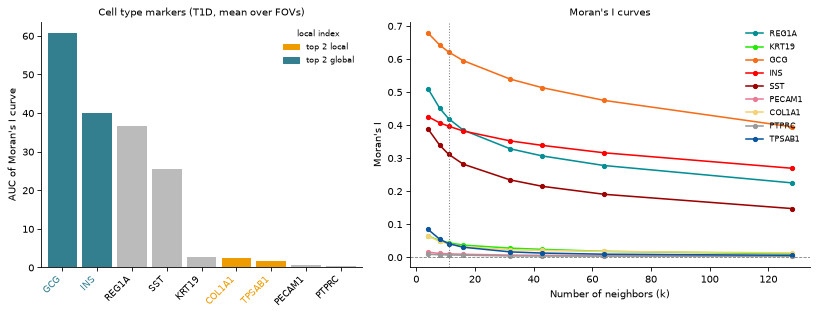

In [8]:
stats_mk = stats.set_index("feature").loc[GENES]
display(stats_mk[["I_min", "I_split", "I_max", "slope_local", "slope_global", "rel_local", "rel_global",
                  "local_index", "auc"]].round(3))
top_mk_local, top_mk_global = isc.pl.top_local_global(adata_cond, n_top=N_TOP_GENES, features=GENES)
print(f"top {N_TOP_GENES} local:  {top_mk_local}")
print(f"top {N_TOP_GENES} global: {top_mk_global}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), gridspec_kw={"width_ratios": [0.8, 1]})
isc.pl.moran_auc(adata_cond, features=GENES, n_top=N_TOP_GENES, ax=axes[0], **CLASS_COLORS,
                 title=f"Cell type markers ({CONDITION}, mean over FOVs)")
isc.pl.moran_curves(adata_cond, genes=GENES, features=GENES, n_top=N_TOP_GENES, palette=GENE_COLORS, ax=axes[1],
                    **CLASS_COLORS, title="Moran's I curves")
plt.tight_layout()
plt.savefig(FIG_DIR / f"local_index_markers_{CONDITION}_split{K_SPLIT}.png", dpi=PLOT_CFG["dpi_save"],
            bbox_inches="tight")
plt.show()

### Curvature on a log2 k axis

On a log2 k axis, a gene whose autocorrelation decays by the same ΔI per doubling of k has a straight Moran
curve: the **chord** from I(k_min) to I(k_max), the reference for "no preferred scale". A **local** gene loses its
autocorrelation within small neighborhoods, so its curve sags *below* the chord (convex); a **global**
(tissue-scale) gene keeps it and drops late, so its curve bulges *above* the chord (concave).

The **gap** at the split, chord − I(`K_SPLIT`) (stats column `chord_gap`), is the local index rescaled:
`chord_gap = local_index · L1·L2 / (L1 + L2)` with L1 = log2(K_SPLIT / k_min) and L2 = log2(k_max / K_SPLIT)
doublings. For a split at the log-midpoint (4 / 16 / 64) the factor is 1. Filled markers: the three scales the
index uses; hollow: the scales it does not.

Right panel: every curve rescaled to run from 1 (k_min) to 0 (k_max), so all genes share one chord, the grey
diagonal, and their curvature is comparable regardless of how strongly autocorrelated they are.

split k = 11: L1 = 1.46, L2 = 3.54 doublings -> chord_gap = 1.03 x local index


,I_min,I_split,I_max,local_index,chord_gap
feature,,,,,
ANXA4,0.2071,0.1257,0.0238,0.0270,0.0279
FGFR3,0.1698,0.1031,0.0220,0.0228,0.0235
COL18A1,0.1193,0.0700,0.0140,0.0180,0.0186
OLFM4,0.1545,0.1035,0.0423,0.0176,0.0182
TTR,0.6601,0.6099,0.3921,-0.0271,-0.0280
GCG,0.6786,0.6211,0.3943,-0.0247,-0.0255
CHGA,0.5468,0.5051,0.3250,-0.0223,-0.0230
INS,0.4251,0.3963,0.2690,-0.0163,-0.0168


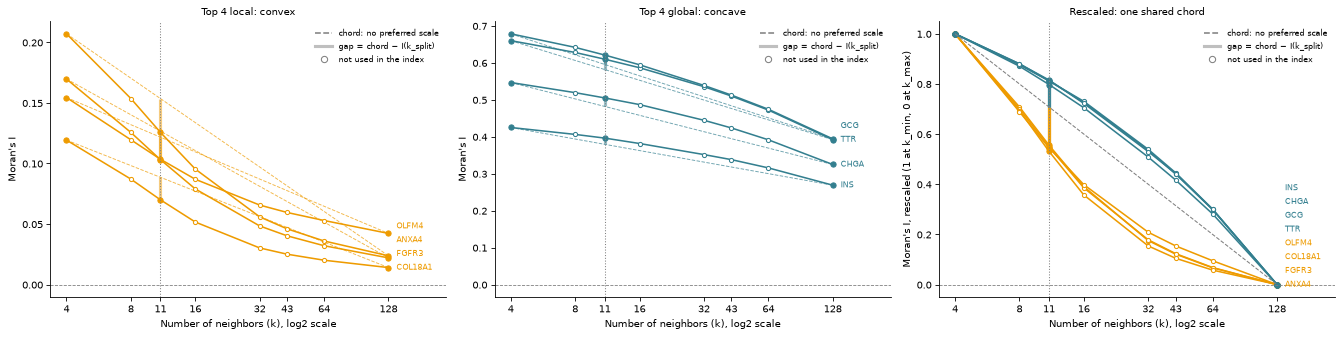

In [9]:
N_CHORD = 4  # genes per class: the chords and gaps of more curves overlap
l1, l2 = np.log2(SPLIT / SCALES[0]), np.log2(SCALES[-1] / SPLIT)
print(f"split {fmt(SPLIT)}: L1 = {l1:.2f}, L2 = {l2:.2f} doublings -> chord_gap = {l1 * l2 / (l1 + l2):.2f} x local index")
display(stats.set_index("feature").loc[top_li_local[:N_CHORD] + top_li_global[:N_CHORD],
                                       ["I_min", "I_split", "I_max", "local_index", "chord_gap"]].round(4))

chord_kw = dict(features=STRUCTURED, n_top=N_CHORD, log_scale=True, chord=True, **CLASS_COLORS)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
isc.pl.moran_curves(adata_cond, genes="local", ax=axes[0], title=f"Top {N_CHORD} local: convex", **chord_kw)
isc.pl.moran_curves(adata_cond, genes="global", ax=axes[1], title=f"Top {N_CHORD} global: concave", **chord_kw)
isc.pl.moran_curves(adata_cond, genes="both", normalize=True, ax=axes[2],
                    title="Rescaled: one shared chord", **chord_kw)
plt.tight_layout()
plt.savefig(FIG_DIR / f"moran_log2_chord_{CONDITION}_split{K_SPLIT}.png", dpi=PLOT_CFG["dpi_save"],
            bbox_inches="tight")
plt.show()

The same for the cell type markers, in their cell type colors.

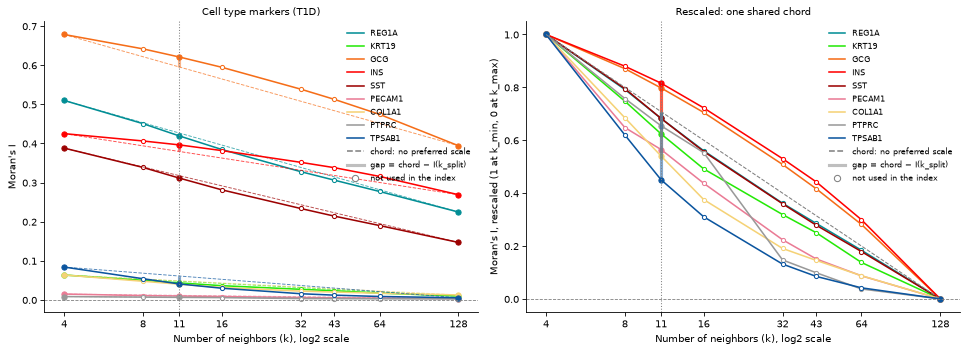

In [10]:
marker_kw = dict(genes=GENES, features=GENES, n_top=N_TOP_GENES, palette=GENE_COLORS, log_scale=True, chord=True,
                 **CLASS_COLORS)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
isc.pl.moran_curves(adata_cond, ax=axes[0], title=f"Cell type markers ({CONDITION})", **marker_kw)
isc.pl.moran_curves(adata_cond, normalize=True, ax=axes[1], title="Rescaled: one shared chord", **marker_kw)
plt.tight_layout()
plt.savefig(FIG_DIR / f"moran_log2_chord_markers_{CONDITION}_split{K_SPLIT}.png", dpi=PLOT_CFG["dpi_save"],
            bbox_inches="tight")
plt.show()

## 2. Is the AUC mostly a measure of overall autocorrelation?

If the AUC is almost fully determined by Moran's I at the smallest scale, it says little about *how* a gene's
structure changes with scale.

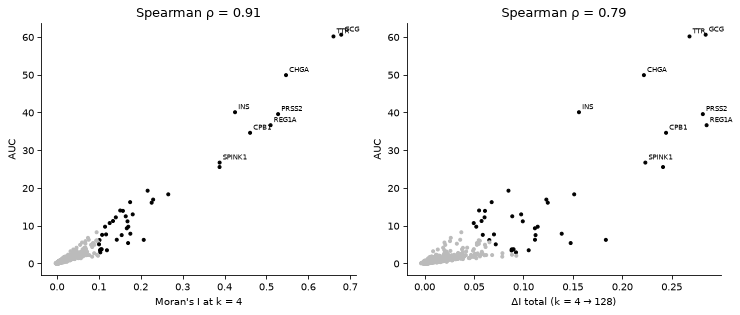

Spearman I(k_min) vs ΔI total: 0.97  (strongly structured genes also have more to lose)


In [11]:
def label_points(ax, x, y, labels, fontsize=7, **kw):
    for xi, yi, lab in zip(x, y, labels):
        ax.annotate(lab, (xi, yi), xytext=(3, 3), textcoords="offset points", fontsize=fontsize, **kw)


rho_auc_imin = spearmanr(stats["auc"], stats["I_min"]).statistic
rho_auc_dtot = spearmanr(stats["auc"], stats["delta_total"]).statistic
rho_imin_dtot = spearmanr(stats["I_min"], stats["delta_total"]).statistic

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
for ax, x, xlab, rho in [
    (axes[0], "I_min", f"Moran's I at {fmt(SCALES[0])}", rho_auc_imin),
    (axes[1], "delta_total", f"ΔI total ({fmt(SCALES[0])} → {SCALES[-1]:.0f})", rho_auc_dtot),
]:
    ax.scatter(stats[x], stats["auc"], s=8, c=np.where(stats["structured"], "k", COLOR_OTHER))
    sub = stats[stats["feature"].isin(top_auc)]
    label_points(ax, sub[x], sub["auc"], sub["feature"])
    ax.set_xlabel(xlab)
    ax.set_ylabel("AUC")
    ax.set_title(f"Spearman ρ = {rho:.2f}")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / f"auc_vs_baseline_{CONDITION}.png", dpi=PLOT_CFG["dpi_save"], bbox_inches="tight")
plt.show()
print(f"Spearman I(k_min) vs ΔI total: {rho_imin_dtot:.2f}  (strongly structured genes also have more to lose)")

## 3. Local vs. global decay

Left: absolute decay, ΔI per doubling of k. Right: relative decay, fraction of the autocorrelation lost in each
range. Points above the diagonal lose more structure within the local component's radius than beyond it.
Grey: genes with mean I(k_min) < `MIN_I` (left only; their relative ΔI is undefined).

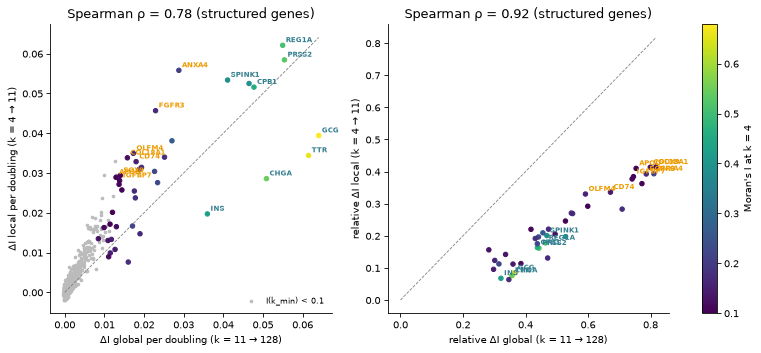

In [12]:
s = stats[stats["structured"]]
top_local = s.sort_values("local_index", ascending=False).head(N_TOP)["feature"].tolist()
top_global_loss = s.sort_values("slope_global", ascending=False).head(N_TOP)["feature"].tolist()
# persistent: strongly structured, and little of it is lost at large scales
persistent = s.sort_values("I_max", ascending=False).head(N_TOP)["feature"].tolist()

rho_abs = spearmanr(s["slope_local"], s["slope_global"]).statistic
rho_rel = spearmanr(s["rel_local"], s["rel_global"]).statistic

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))
for ax, (x, y, xlab, ylab, rho) in zip(axes, [
    ("slope_global", "slope_local", f"ΔI global per doubling ({fmt(SPLIT)} → {SCALES[-1]:.0f})",
     f"ΔI local per doubling ({fmt(SCALES[0])} → {SPLIT:.0f})", rho_abs),
    ("rel_global", "rel_local", f"relative ΔI global ({fmt(SPLIT)} → {SCALES[-1]:.0f})",
     f"relative ΔI local ({fmt(SCALES[0])} → {SPLIT:.0f})", rho_rel),
]):
    if x == "slope_global":  # relative ΔI is undefined for genes without autocorrelation -> absolute panel only
        ns = stats[~stats["structured"]]
        ax.scatter(ns[x], ns[y], s=6, color=COLOR_OTHER, label=f"I(k_min) < {MIN_I}")
    sca = ax.scatter(s[x], s[y], s=18, c=s["I_min"], cmap=CMAP, vmin=MIN_I, zorder=3)
    lim = [min(s[x].min(), s[y].min(), 0), max(s[x].max(), s[y].max())]
    ax.plot(lim, lim, ls="--", lw=0.8, color="grey")
    for genes, c in [(top_local, COLOR_LOCAL), (persistent, COLOR_GLOBAL)]:
        sub = s[s["feature"].isin(genes)]
        label_points(ax, sub[x], sub[y], sub["feature"], color=c, fontweight="bold")
    ax.set_xlabel(xlab)
    ax.set_ylabel(ylab)
    ax.set_title(f"Spearman ρ = {rho:.2f} (structured genes)")
    ax.spines[["top", "right"]].set_visible(False)
fig.colorbar(sca, ax=axes, label=f"Moran's I at {fmt(SCALES[0])}", fraction=0.025)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
plt.savefig(FIG_DIR / f"delta_local_vs_global_{CONDITION}_split{K_SPLIT}.png", dpi=PLOT_CFG["dpi_save"],
            bbox_inches="tight")
plt.show()

## 4. Gene rankings

- **local index** = ΔI local − ΔI global (per doubling): genes losing their structure mainly within the radius.
- **ΔI global** (per doubling): genes losing structure at tissue scale.
- **I(k_max)**: genes that keep their autocorrelation up to the largest neighborhood (persistent / global).

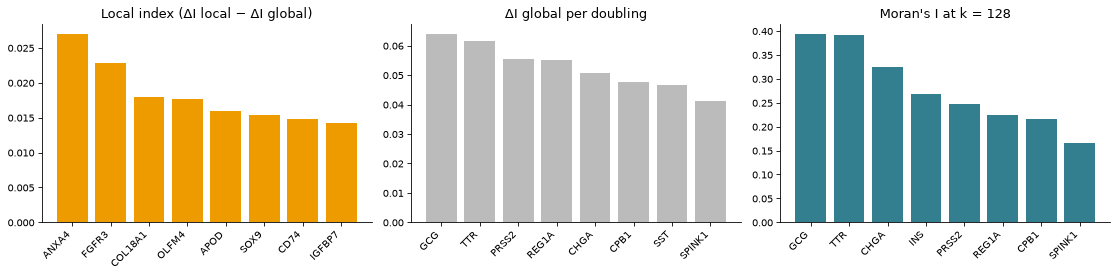

,top local index,top ΔI global,most persistent
0,ANXA4,GCG,GCG
1,FGFR3,TTR,TTR
2,COL18A1,PRSS2,CHGA
3,OLFM4,REG1A,INS
4,APOD,CHGA,PRSS2
5,SOX9,CPB1,REG1A
6,CD74,SST,CPB1
7,IGFBP7,SPINK1,SPINK1


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, genes, color, title in [
    (axes[0], "local_index", top_local, COLOR_LOCAL, "Local index (ΔI local − ΔI global)"),
    (axes[1], "slope_global", top_global_loss, COLOR_OTHER, "ΔI global per doubling"),
    (axes[2], "I_max", persistent, COLOR_GLOBAL, f"Moran's I at {fmt(SCALES[-1])}"),
]:
    v = s.set_index("feature").loc[genes, col]
    ax.bar(v.index, v.values, color=color)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45)
    for lbl in ax.get_xticklabels():
        lbl.set_ha("right")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG_DIR / f"gene_rankings_{CONDITION}_split{K_SPLIT}.png", dpi=PLOT_CFG["dpi_save"], bbox_inches="tight")
plt.show()

display(pd.DataFrame({"top local index": top_local, "top ΔI global": top_global_loss, "most persistent": persistent}))

## 5. Moran curves and spatial patterns: most local vs. most persistent genes

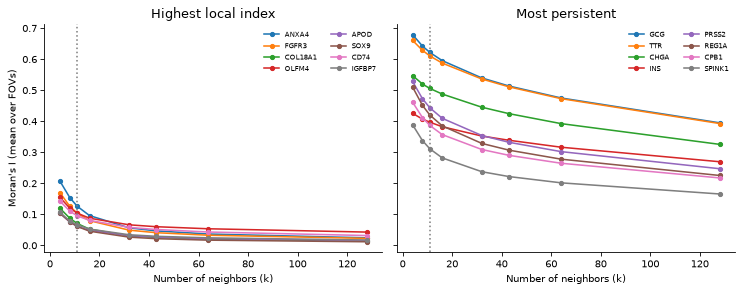

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, genes, title in [(axes[0], top_local, "Highest local index"), (axes[1], persistent, "Most persistent")]:
    for g, c in zip(genes, plt.get_cmap("tab10").colors):
        ax.plot(SCALES, I.loc[g], marker="o", ms=4, color=c, label=g)
    ax.axvline(SPLIT, ls=":", color="grey")
    ax.set_title(title)
    ax.set_xlabel(XLABEL)
    ax.legend(frameon=False, fontsize=7, ncol=2)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Moran's I (mean over FOVs)")
plt.tight_layout()
plt.savefig(FIG_DIR / f"curves_local_vs_persistent_{CONDITION}_split{K_SPLIT}.png", dpi=PLOT_CFG["dpi_save"],
            bbox_inches="tight")
plt.show()

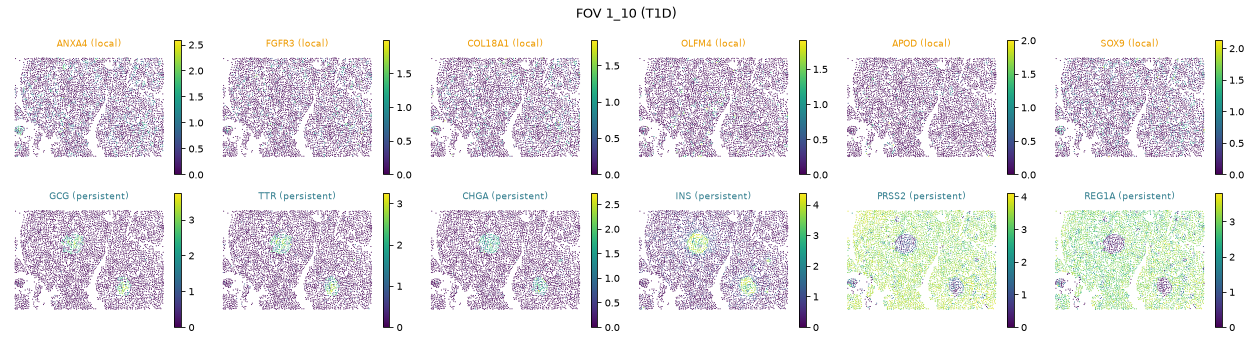

In [15]:
SLIDE = SLIDES[CONDITION]
adata_slide = adata_cond[adata_cond.obs[LIBRARY_KEY] == SLIDE]
coords = adata_slide.obsm["spatial"]
n = min(N_TOP, 6)
fig, axes = plt.subplots(2, n, figsize=(2.8 * n, 4.6))
for r, (genes, title) in enumerate([(top_local[:n], "local"), (persistent[:n], "persistent")]):
    X = adata_slide[:, genes].X if LAYER is None else adata_slide[:, genes].layers[LAYER]
    X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)
    for j, g in enumerate(genes):
        ax = axes[r, j]
        order = np.argsort(X[:, j])
        sca = ax.scatter(coords[order, 0], coords[order, 1], c=X[order, j], s=1, cmap=CMAP, linewidths=0)
        fig.colorbar(sca, ax=ax, fraction=0.046, pad=0.02)
        ax.set_title(f"{g} ({title})", fontsize=9, color=COLOR_LOCAL if r == 0 else COLOR_GLOBAL)
        ax.set_aspect("equal")
        ax.axis("off")
plt.suptitle(f"FOV {SLIDE} ({CONDITION})")
plt.tight_layout()
plt.savefig(FIG_DIR / f"spatial_local_vs_persistent_{CONDITION}_split{K_SPLIT}.png", dpi=PLOT_CFG["dpi_save"],
            bbox_inches="tight")
plt.show()

## 6. Sensitivity to the local / global split

Rank agreement (Spearman) of the local index for every possible split, in particular the local component's radius
(`K_SPLIT`) vs. its full reach over all GCN layers (`K_REACH`).

In [16]:
splits = SCALES[1:-1]
li = pd.DataFrame({
    f"{s_:.0f}": isc.tl.delta_from_profile(prof, split=s_).set_index("feature")
    .pipe(lambda d: d["slope_local"] - d["slope_global"]).loc[s["feature"]]
    for s_ in splits
})
print(f"split = {SPLIT:.0f}: radius (1 GCN layer), split = {SPLIT_REACH:.0f}: reach ({NUM_LAYERS} GCN layers)")
display(li.corr(method="spearman").round(2))
display(pd.DataFrame({c: li[c].sort_values(ascending=False).head(N_TOP).index.tolist() for c in li.columns}))

split = 11: radius (1 GCN layer), split = 43: reach (2 GCN layers)


,8,11,16,32,43,64
8,1.00,0.98,0.96,0.95,0.94,0.94
11,0.98,1.00,1.00,0.99,0.98,0.98
16,0.96,1.00,1.00,0.99,0.98,0.98
32,0.95,0.99,0.99,1.00,1.00,0.99
43,0.94,0.98,0.98,1.00,1.00,1.00
64,0.94,0.98,0.98,0.99,1.00,1.00


,8,11,16,32,43,64
0,ANXA4,ANXA4,ANXA4,ANXA4,ANXA4,ANXA4
1,FGFR3,FGFR3,FGFR3,FGFR3,FGFR3,FGFR3
2,OLFM4,COL18A1,COL18A1,COL18A1,COL18A1,COL18A1
3,COL18A1,OLFM4,OLFM4,SOX9,SOX9,SOX9
4,IGFBP7,APOD,SOX9,OLFM4,OLFM4,IGF2
5,CD74,SOX9,APOD,APOD,SPP1,OLFM4
6,APOD,CD74,IGFBP7,IGFBP7,IGF2,APOD
7,SOX9,IGFBP7,SPP1,SPP1,IGFBP7,SPP1


## 7. ND vs. T1D

Local index of each gene in ND and T1D donors (split at `K_SPLIT` in both). Genes structured in both conditions;
labelled: the genes whose local index changes most.

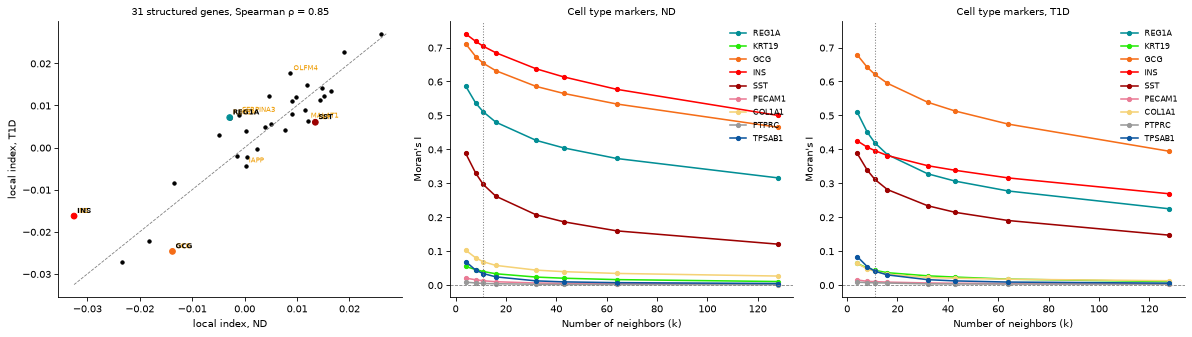

,local index ND,local index T1D,Δ (T1D − ND)
feature,,,
GCG,-0.014,-0.025,-0.011
SST,0.013,0.006,-0.007
MALAT1,0.012,0.006,-0.006
IAPP,0.000,-0.004,-0.004
SERPINA3,-0.001,0.008,0.009
OLFM4,0.009,0.018,0.009
REG1A,-0.003,0.007,0.010
INS,-0.033,-0.016,0.016


In [17]:
both = pd.concat({c: stats_all[c].set_index("feature") for c in CONDITIONS}, axis=1)
both = both[both[("ND", "structured")] & both[("T1D", "structured")]]
d_li = (both[("T1D", "local_index")] - both[("ND", "local_index")]).sort_values()
changed = d_li.index[:N_TOP // 2].tolist() + d_li.index[-(N_TOP // 2):].tolist()
rho_cond = spearmanr(both[("ND", "local_index")], both[("T1D", "local_index")]).statistic

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1, 1, 1]})
ax = axes[0]
ax.scatter(both[("ND", "local_index")], both[("T1D", "local_index")], s=10, color="k")
lim = [both[[("ND", "local_index"), ("T1D", "local_index")]].values.min(),
       both[[("ND", "local_index"), ("T1D", "local_index")]].values.max()]
ax.plot(lim, lim, ls="--", lw=0.8, color="grey")
sub = both.loc[changed]
label_points(ax, sub[("ND", "local_index")], sub[("T1D", "local_index")], changed, color=COLOR_LOCAL)
sub = both.loc[[g for g in GENES if g in both.index]]
ax.scatter(sub[("ND", "local_index")], sub[("T1D", "local_index")], s=30, zorder=3,
           c=[GENE_COLORS[g] for g in sub.index])
label_points(ax, sub[("ND", "local_index")], sub[("T1D", "local_index")], sub.index, fontweight="bold")
ax.set_xlabel("local index, ND")
ax.set_ylabel("local index, T1D")
ax.set_title(f"{len(both)} structured genes, Spearman ρ = {rho_cond:.2f}", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
for ax, cond in zip(axes[1:], CONDITIONS):
    isc.pl.moran_curves(adatas[cond], genes=GENES, features=GENES, n_top=N_TOP_GENES, palette=GENE_COLORS, ax=ax,
                        **CLASS_COLORS, title=f"Cell type markers, {cond}")
ylim = (min(a.get_ylim()[0] for a in axes[1:]), max(a.get_ylim()[1] for a in axes[1:]))
for a in axes[1:]:
    a.set_ylim(ylim)
plt.tight_layout()
plt.savefig(FIG_DIR / f"nd_vs_t1d_split{K_SPLIT}.png", dpi=PLOT_CFG["dpi_save"], bbox_inches="tight")
plt.show()

display(pd.DataFrame({"local index ND": both.loc[changed, ("ND", "local_index")],
                      "local index T1D": both.loc[changed, ("T1D", "local_index")],
                      "Δ (T1D − ND)": d_li.loc[changed]}).round(3))